# Expensive coffee, richer farmers?
*Assignment 4 - Economics*

## Question 1: Understand and explore the market

**Data:** `coffee_market.csv` — 300 independent selling periods in a stylised wholesale market for one grade of green coffee (synthetic teaching data).

> Assumptions given in the brief: price-taking buyers and sellers, market clearing, fixed quality, no inventory carry-over. `growing_conditions` is independent of buyers' preferences, incomes and unobserved demand disturbances; `buyer_activity` does not directly change producers' costs.

### 1.1 First approach to data

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

coff_mark = pd.read_csv('data/coffee_market.csv')

# Colours (blue / orange / aqua) + different marker shapes, so groups never rely on colour alone
BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
coff_mark.head()

,period_id,period_index,price_usd_kg,quantity_kt,growing_conditions,buyer_activity
0,M001,1,10.837531,133.302350,1.5,2.391855
1,M002,2,8.915661,67.150820,-1.5,-2.516137
2,M003,3,11.694981,88.019068,-1.5,-0.195789
3,M004,4,10.394216,101.971595,0.0,0.117742
4,M005,5,7.323098,95.714836,1.5,-1.148320


In [3]:
audit = pd.Series({
    "rows": len(coff_mark),
    "columns": coff_mark.shape[1],
    "missing cells": int(coff_mark.isna().sum().sum()),
    "duplicated rows": int(coff_mark.duplicated().sum()),
    "unique period_id": coff_mark["period_id"].nunique(),
    "period_id matches period_index": bool((coff_mark["period_id"].str[1:].astype(int) == coff_mark["period_index"]).all()),
    "non-positive prices": int((coff_mark["price_usd_kg"] <= 0).sum()),
    "non-positive quantities": int((coff_mark["quantity_kt"] <= 0).sum()),
    "distinct growing_conditions values": sorted(coff_mark["growing_conditions"].unique().tolist()),
    "distinct buyer_activity values": coff_mark["buyer_activity"].nunique(),
}, name="value")
display(audit.to_frame())
display(coff_mark.dtypes.to_frame("dtype"))
coff_mark["growing_conditions"].value_counts().sort_index().rename("periods").to_frame()

,value
rows,300
columns,6
missing cells,0
duplicated rows,0
unique period_id,300
period_id matches period_index,True
non-positive prices,0
non-positive quantities,0
distinct growing_conditions values,"[-1.5, 0.0, 1.5]"
distinct buyer_activity values,300


,dtype
period_id,str
period_index,int64
price_usd_kg,float64
quantity_kt,float64
growing_conditions,float64
buyer_activity,float64


,periods
growing_conditions,
-1.5,100
0.0,100
1.5,100


> The data is healthy and the description matches the content. No missing values or duplicated rows. In general is coherent as all prices and quantities are positive. This first step is fundamental so we can conclude all the analysis that's about to come represents behaviours and not data mistakes. 

**Important note**: Period id will not be analyzed as time because the description of the variable says "The index is not a historical trend". So time series are no part of this analysis.

### 1.2 Sales revenue and descriptive

Revenue = price × quantity. Units: (US\$ per kg) × (thousand tonnes) = (US\$/kg) × (10⁶ kg) = **million US\$** per selling period.

In [4]:
coff_mark["revenue_musd"] = coff_mark["price_usd_kg"] * coff_mark["quantity_kt"]

vars_ = {"price_usd_kg": "Price (US$/kg)",
         "quantity_kt": "Quantity (thousand t)",
         "revenue_musd": "Revenue (million US$)"}
desc = (coff_mark[list(vars_)].describe(percentiles=[.25, .5, .75]).T
          .rename(index=vars_)
          [["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])
desc["CV (std/mean)"] = desc["std"] / desc["mean"]
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,CV (std/mean)
Price (US$/kg),300.0,10.01,2.22,5.17,8.50,10.03,11.47,14.99,0.22
Quantity (thousand t),300.0,100.01,18.46,64.15,85.27,100.40,115.42,138.60,0.18
Revenue (million US$),300.0,1022.83,357.98,382.92,718.70,969.61,1300.92,1858.19,0.35


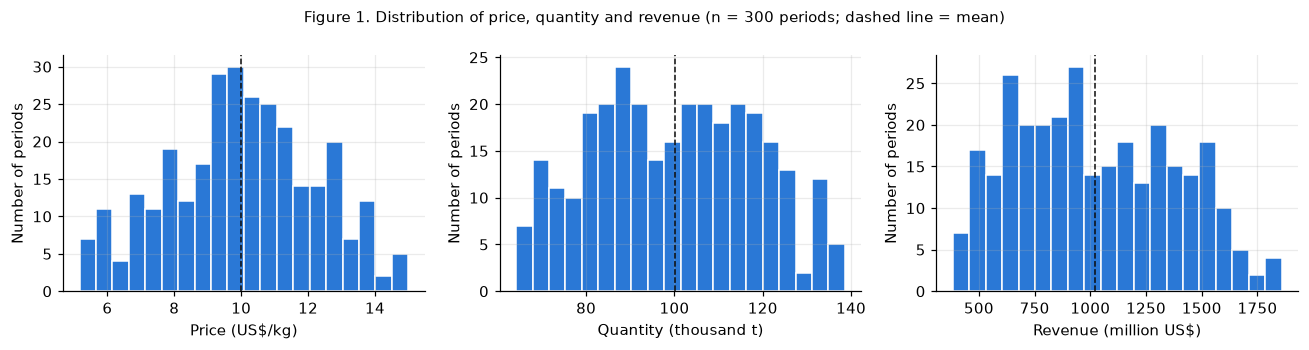

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, (col, label) in zip(axes, vars_.items()):
    ax.hist(coff_mark[col], bins=20, color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(coff_mark[col].mean(), color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel(label); ax.set_ylabel("Number of periods")
fig.suptitle("Figure 1. Distribution of price, quantity and revenue (n = 300 periods; dashed line = mean)", fontsize=10)
fig.tight_layout(); plt.show()

Here we check for distribution (skew), outliers and variable fluctuation:
* The spread of the renvenue is much bigger than that from Price and Quantity: 35% vs 22% and 18% 
    * Typical price: 10 USD per kg
    * Typical quantity: 100 thousands of tonnes
    * Typical revenue: 1,022 million of USD
* We don't observe any extreme periods so far

### 1.3 Price-quantity relationship

We also fit the simplest linear relationship, $Q = a + b\,P$, treating all 300 points alike. This is the "naive" answer to *how does quantity move with price?*

Pooled fit: Q = 55.1 + 4.49·P   (kt per US$/kg)
Correlation(P, Q) = 0.54
'Elasticity' implied at the means (P̄=10.01, Q̄=100.0): 0.45


,n,P_mean,Q_mean
growing_conditions,,,
-1.5,100,11.57,91.69
0.0,100,10.20,102.04
1.5,100,8.25,106.31


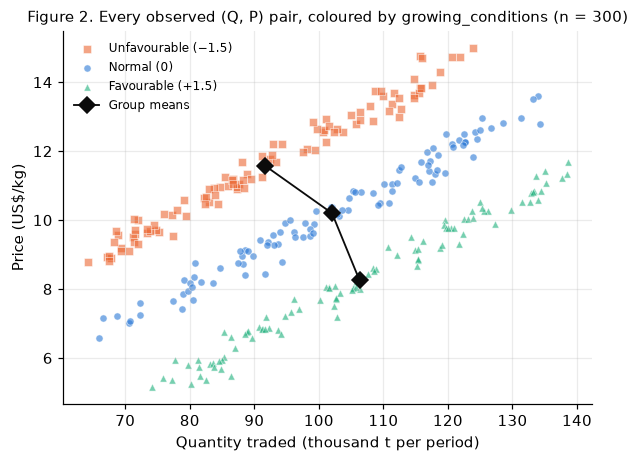

In [6]:
P, Q = coff_mark["price_usd_kg"], coff_mark["quantity_kt"]
b, a = np.polyfit(P, Q, 1)                       # Q = a + b*P
r = P.corr(Q)
naive_elast = b * P.mean() / Q.mean()            # slope × (P̄ / Q̄)

print(f"Pooled fit: Q = {a:.1f} + {b:.2f}·P   (kt per US$/kg)")
print(f"Correlation(P, Q) = {r:.2f}")
print(f"'Elasticity' implied at the means (P̄={P.mean():.2f}, Q̄={Q.mean():.1f}): {naive_elast:.2f}")

# Same points, coloured by growing_conditions (supply shifter), plus each group's mean
groups = {-1.5: ("Unfavourable (−1.5)", ORANGE, "s"), 0.0: ("Normal (0)", BLUE, "o"), 1.5: ("Favourable (+1.5)", AQUA, "^")}
means = (coff_mark.groupby("growing_conditions")
           .agg(n=("price_usd_kg", "size"), P_mean=("price_usd_kg", "mean"), Q_mean=("quantity_kt", "mean")))
display(means.round(2))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
for g, (label, col, mk) in groups.items():
    sub = coff_mark[coff_mark["growing_conditions"] == g]
    ax.scatter(sub["quantity_kt"], sub["price_usd_kg"], s=22, color=col, marker=mk,
               alpha=0.6, edgecolor="white", linewidth=0.5, label=label)
ax.plot(means["Q_mean"], means["P_mean"], color=INK, marker="D", markersize=7, linewidth=1.2, label="Group means")
ax.set_xlabel("Quantity traded (thousand t per period)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 2. Every observed (Q, P) pair, coloured by growing_conditions (n = 300)", fontsize=10)
ax.legend(frameon=False, loc="upper left", fontsize=8); plt.show()

**What do we see when we colour the dots by `growing_conditions` (Figure 2)?**

> **First conclusion:** As the price increases, the quantity traded decreases. But it's not an isolated effect

* The graph was initially analyzed with an overall mean, but it does not make that much sense after plotting: The three groups of `growing_conditions` have clearly different behaviours

- **The cloud is really three bands.** Each harvest level forms its own narrow, upward-sloping band, and the bands are stacked side by side. What looks like a noisy pooled relationship (correlation 0.54) is mostly the mix of three different harvest situations.

- **Better harvests sit lower and further right.** The same price comes with more coffee traded when growing conditions are good. This is what we would expect if good weather shifts supply outward.

- **Within each band, price and quantity rise together.** Growing conditions are fixed inside a band, so this co-movement must come from the other driver, `buyer_activity` (demand shifting along a given supply).

- **The group means move the opposite way.** Going from poor to good harvests, the average price falls (11.57 → 10.20 → 8.25 US\$/kg) while the average quantity rises (91.7 → 102.0 → 106.3 kt). Since `growing_conditions` is independent of buyers, average demand is the same in all three groups. The diamonds therefore show how buyers react when only supply changes: cheaper coffee, more bought.

In [7]:
cols = ["price_usd_kg", "quantity_kt", "revenue_musd", "growing_conditions", "buyer_activity"]
coff_mark[cols].corr().round(2)

,price_usd_kg,quantity_kt,revenue_musd,growing_conditions,buyer_activity
price_usd_kg,1.00,0.54,0.89,-0.61,0.79
quantity_kt,0.54,1.00,0.85,0.32,0.93
revenue_musd,0.89,0.85,1.00,-0.21,0.97
growing_conditions,-0.61,0.32,-0.21,1.00,-0.02
buyer_activity,0.79,0.93,0.97,-0.02,1.00


> Price and quantity are both strongly correlated with `buyer_activity`
>
> `growing_conditions` correlates *negatively* with price but *positively* with quantity. Simpler words: positive grow conditions establish an scenario for cheaper and more abundant coffee.

In [8]:
by_gc = (coff_mark.groupby("growing_conditions")
           .agg(periods=("price_usd_kg", "size"),
                mean_price=("price_usd_kg", "mean"),
                mean_quantity=("quantity_kt", "mean"),
                mean_revenue=("revenue_musd", "mean"),
                mean_buyer_activity=("buyer_activity", "mean"))
           .rename(index={-1.5: "Unfavourable (−1.5)", 0.0: "Normal (0)", 1.5: "Favourable (+1.5)"}))
by_gc.round(2)

,periods,mean_price,mean_quantity,mean_revenue,mean_buyer_activity
growing_conditions,,,,,
Unfavourable (−1.5),100,11.57,91.69,1088.90,-0.07
Normal (0),100,10.20,102.04,1070.36,0.20
Favourable (+1.5),100,8.25,106.31,909.22,-0.15


> Revenue is higher when the growing conditions are worse: High price, low quantity
>
> `growing_conditions` correlates *negatively* with price but *positively* with quantity. Simpler words: positive grow conditions establish an scenario for cheaper and more abundant coffee.

---
# Question 2: Develop an equilibrium explanation

## 2.1 What an observed (Q, P) pair represents

In each selling period there is a demand curve $D(p; \text{buyer activity}, u_t)$ and a supply curve $S(p; \text{growing conditions}, v_t)$, where $u_t$ and $v_t$ are disturbances we **do not observe**. With price-taking and market clearing, the recorded pair $(Q_t, P_t)$ solves

$$D(P_t;\ \text{buyer activity}_t,\ u_t) \;=\; S(P_t;\ \text{growing conditions}_t,\ v_t) \;=\; Q_t .$$

So each row is the **intersection** of two curves. It is not a point that buyers picked on their own, and it is not one that sellers picked on their own.

**Movement along a curve and shift of a curve**
- *Movement along* a curve: the price changes while everything else in that curve's equation stays fixed (same buyer activity and same $u_t$ for demand). That is the thing we want to measure: "if the price rose, how much less would buyers purchase?"
- *Shift* of a curve: one of the conditions behind it changes (buyer activity, growing conditions, or an unobserved disturbance), so the whole curve moves. At **every** price, the quantity is different.

## 2.2 Two alternative explanations for a higher coffee price

| | **Explanation A: stronger demand** | **Explanation B: weaker supply (bad harvest)** |
|---|---|---|
| What changes | `buyer_activity` ↑: foreign buyers want more at every price | `growing_conditions` ↓: less coffee is worth harvesting at every price |
| Curve that shifts | Demand shifts **right** | Supply shifts **left** |
| Movement along | the **unchanged supply** curve | the **unchanged demand** curve |
| Price | ↑ | ↑ |
| Quantity | **↑** | **↓** |
| Seller revenue | ↑ (P and Q both rise) | ambiguous: depends on how strongly buyers react to price |

**Key:** the price rises in both cases, so the price alone cannot tell the two explanations apart. The direction of the **quantity** change can.

> The diagrams below use *illustrative* linear curves in coffee-like units. They are not estimates

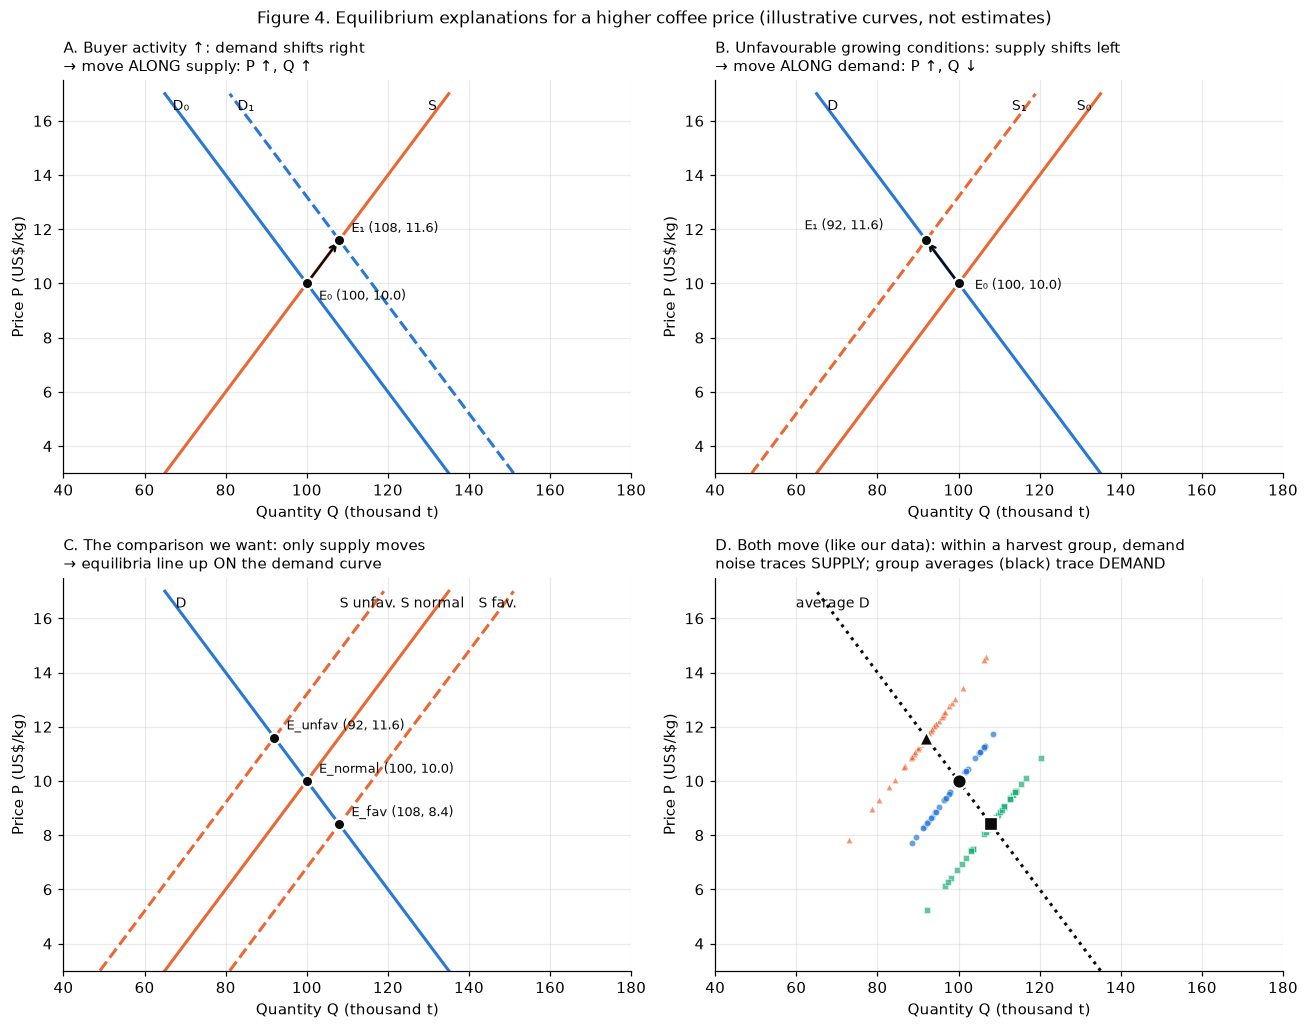

In [9]:
def demand(P, shift=0):  return 150 + shift - 5 * P     # illustrative only
def supply(P, shift=0):  return 50 + shift + 5 * P      # illustrative only
def eq(dS=0, dD=0):      # solve 150+dD-5P = 50+dS+5P
    P = (100 + dD - dS) / 10
    return demand(P, dD), P

Pg = np.linspace(3, 17, 100)
def curve(ax, f, shift, color, label, ls="-"):
    ax.plot(f(Pg, shift), Pg, color=color, lw=2, ls=ls)
    q = f(16.2, shift); ax.text(q, 16.4, label, color=INK, fontsize=9, ha="center")
def point(ax, Q, P, name, dx=3, dy=-0.6):
    ax.scatter([Q], [P], s=55, color=INK, zorder=5, edgecolor="white", linewidth=1.5)
    ax.text(Q + dx, P + dy, f"{name} ({Q:.0f}, {P:.1f})", fontsize=8.5, color=INK)
def frame(ax, title):
    ax.set_xlim(40, 180); ax.set_ylim(3, 17.5)
    ax.set_xlabel("Quantity Q (thousand t)"); ax.set_ylabel("Price P (US$/kg)")
    ax.set_title(title, fontsize=10, loc="left")

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))

# A: demand shift
ax = axes[0, 0]
curve(ax, supply, 0, ORANGE, "S")
curve(ax, demand, 0, BLUE, "D₀"); curve(ax, demand, 16, BLUE, "D₁", ls="--")
Q0, P0 = eq(); Q1, P1 = eq(dD=16)
point(ax, Q0, P0, "E₀"); point(ax, Q1, P1, "E₁", dy=0.3)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "A. Buyer activity ↑: demand shifts right\n→ move ALONG supply: P ↑, Q ↑")

# B: supply shift
ax = axes[0, 1]
curve(ax, demand, 0, BLUE, "D")
curve(ax, supply, 0, ORANGE, "S₀"); curve(ax, supply, -16, ORANGE, "S₁", ls="--")
Q1, P1 = eq(dS=-16)
point(ax, Q0, P0, "E₀", dx=4, dy=-0.2); point(ax, Q1, P1, "E₁", dx=-30, dy=0.4)
ax.annotate("", xy=(Q1, P1), xytext=(Q0, P0), arrowprops=dict(arrowstyle="->", color=INK, lw=1.5))
frame(ax, "B. Unfavourable growing conditions: supply shifts left\n→ move ALONG demand: P ↑, Q ↓")

# C: supply shifts only, demand fixed -> equilibria trace demand
ax = axes[1, 0]
curve(ax, demand, 0, BLUE, "D")
for s, lab in [(-16, "S unfav."), (0, "S normal"), (16, "S fav.")]:
    curve(ax, supply, s, ORANGE, lab, ls="-" if s == 0 else "--")
pts = [eq(dS=s) for s in (-16, 0, 16)]
for (q, p), lab in zip(pts, ["E_unfav", "E_normal", "E_fav"]):
    point(ax, q, p, lab, dx=3, dy=0.3)
frame(ax, "C. The comparison we want: only supply moves\n→ equilibria line up ON the demand curve")

# D: both shift -> each supply curve traced by demand noise
ax = axes[1, 1]
rng = np.random.default_rng(1)
for s, colr, mk in [(-16, ORANGE, "^"), (0, BLUE, "o"), (16, AQUA, "s")]:
    dshift = rng.normal(0, 14, 40)
    qs, ps = zip(*[eq(dS=s, dD=d) for d in dshift])
    ax.scatter(qs, ps, s=18, color=colr, marker=mk, alpha=0.7, edgecolor="white", linewidth=0.4)
    q, p = eq(dS=s); ax.scatter([q], [p], s=90, color=INK, marker=mk, zorder=5, edgecolor="white", linewidth=1.5)
curve(ax, demand, 0, INK, "average D", ls=":")
frame(ax, "D. Both move (like our data): within a harvest group, demand\nnoise traces SUPPLY; group averages (black) trace DEMAND")

fig.suptitle("Figure 4. Equilibrium explanations for a higher coffee price (illustrative curves, not estimates)", fontsize=11)
fig.tight_layout(); plt.show()

## 2.3 The proposed comparison

Compare market outcomes **across growing-conditions groups** (unfavourable −1.5, normal 0, favourable +1.5), using each group's **average** price and quantity. The change in average quantity divided by the change in average price, between harvest groups, measures how buyers respond to price: a movement along demand.

**It is informative** because growing conditions shift **supply only**. Comparing harvest groups therefore moves the market *along* the demand curve, exactly as in panel C.

| | |
|---|---|
| **What changes across the groups** | Growing conditions → the supply curve → equilibrium price (and, through it, quantity). |
| **What must remain comparable** | Everything behind demand: buyer activity, buyers' incomes and preferences, outside options, and the *unobserved* demand disturbances $u_t$. Also the product (fixed quality) and the market (same buyers and sellers). |
| **Assumptions that justify it** | (1) **Relevance**: growing conditions really shift supply, so prices differ across groups. (2) **Exclusion**: growing conditions affect buyers only through the price; they do not enter the demand curve. (3) **Independence**: growing conditions are unrelated to buyer activity and to unobserved demand shocks.  (4) A **stable demand curve**, approximately linear over the observed range. |

## 2.4 What if demand also moves for reasons we do not observe?

Demand disturbances $u_t$ do not ruin the comparison, as long as they are **unrelated to growing conditions**:
- In any single period, demand noise moves the point off the "average" demand curve, so one period on its own tells us little.
- But weather does not "know" what buyers are doing. Each harvest group is therefore a mix of good, normal and bad demand periods, **in the same proportions** on average. Averaging within each group cancels the demand noise (black markers in panel D), and the remaining difference between group averages is caused by supply.

**When it would fail:**
- If growing conditions were correlated with demand. For example, a weather event that also hits buyers' economies, or buyers who stockpile when they hear about a bad harvest.
- If groups were too small for the averaging to work. Here we have 100 periods per group.
- If supply shifted for other reasons that happen to coincide with demand shocks.

---
# Question 3: Measure the demand response

## 3.1 The idea

Weather moves the market **along** the demand curve (Q2, panel C). So:

$$\text{demand slope} \;=\; \frac{\Delta\ \text{average quantity across harvest groups}}{\Delta\ \text{average price across harvest groups}} \quad [\text{kt per US\$/kg}]$$

We implement this in two versions:
1. **Simple comparison:** raw group means, unfavourable versus favourable harvest. No modelling at all.
2. **Adjusted comparison:** the same ratio after removing the part of each group's P and Q explained by the *observed* demand shifter `buyer_activity`. Buyer activity is independent of the weather, so this does not change *what* we measure. It removes noise and the small chance imbalances between groups.

In [10]:
gm = coff_mark.groupby("growing_conditions")[["price_usd_kg", "quantity_kt", "buyer_activity"]].mean()
dQ = gm.loc[-1.5, "quantity_kt"] - gm.loc[1.5, "quantity_kt"]
dP = gm.loc[-1.5, "price_usd_kg"] - gm.loc[1.5, "price_usd_kg"]
slope_simple = dQ / dP
print("Unfavourable vs favourable harvest (raw group means):")
print(f"  ΔQ = {dQ:.2f} kt,  ΔP = {dP:.2f} US$/kg  →  slope = {slope_simple:.2f} kt per US$/kg")

Unfavourable vs favourable harvest (raw group means):
  ΔQ = -14.63 kt,  ΔP = 3.32 US$/kg  →  slope = -4.40 kt per US$/kg


### Adjusting for observed buyer activity

For each harvest group we fit two straight lines, quantity on buyer activity and price on buyer activity, and read off the predicted Q and P **at buyer_activity = 0** (reference demand conditions). This gives three equilibria with the observed demand conditions held fixed at the same level.

Doing all three groups at once is equivalent to two regressions, each with the weather and buyer activity as regressors:
- $Q = \alpha_Q + \gamma_Q\,G + \delta_Q\,B$
- $P = \alpha_P + \gamma_P\,G + \delta_P\,B$

$\gamma_Q$ is how much **quantity** moves when the weather improves by one point, and $\gamma_P$ is how much **price** moves for the same improvement. Because the weather only moves supply, their ratio $\gamma_Q/\gamma_P$ is the demand slope.

In [11]:
def ols(y, *xs):
    X = np.column_stack([np.ones(len(y)), *xs])
    return np.linalg.lstsq(X, y, rcond=None)[0]

def demand_slope(d, adjust=True):
    G, B = d["growing_conditions"], d["buyer_activity"]
    if adjust:
        gQ = ols(d["quantity_kt"], G, B)[1]; gP = ols(d["price_usd_kg"], G, B)[1]
    else:
        gQ = ols(d["quantity_kt"], G)[1];    gP = ols(d["price_usd_kg"], G)[1]
    return gQ / gP

cQ = ols(coff_mark["quantity_kt"], coff_mark["growing_conditions"], coff_mark["buyer_activity"])
cP = ols(coff_mark["price_usd_kg"], coff_mark["growing_conditions"], coff_mark["buyer_activity"])
slope_adj = cQ[1] / cP[1]
print(f"Weather effect on Q: {cQ[1]:+.2f} kt per point of growing conditions")
print(f"Weather effect on P: {cP[1]:+.2f} US$/kg per point of growing conditions")
print(f"Adjusted demand slope = {cQ[1]:.2f} / {cP[1]:.2f} = {slope_adj:.2f} kt per US$/kg")

# adjusted group equilibria at buyer_activity = 0
adj = pd.DataFrame({g: {"Q at B=0": ols(d["quantity_kt"], d["buyer_activity"])[0],
                        "P at B=0": ols(d["price_usd_kg"], d["buyer_activity"])[0]}
                    for g, d in coff_mark.groupby("growing_conditions")}).T
adj.index.name = "growing_conditions"
adj.round(2)

Weather effect on Q: +5.16 kt per point of growing conditions
Weather effect on P: -1.08 US$/kg per point of growing conditions
Adjusted demand slope = 5.16 / -1.08 = -4.78 kt per US$/kg


,Q at B=0,P at B=0
growing_conditions,,
-1.5,92.34,11.64
0.0,99.95,9.99
1.5,107.86,8.40


## 3.2 Uncertainty: how much could these numbers move with a different sample?

We use a **bootstrap**: we draw 300 periods *with replacement* from our 300, recompute the slope, and repeat 2,000 times. The spread of those slopes shows how much the estimate depends on which periods we happened to observe. We resample whole periods because the brief says they are independent. 

In [12]:
rng = np.random.default_rng(2026)
boot = {"Simple (raw group means)": [], "Adjusted for buyer activity": []}
for _ in range(2000):
    d = coff_mark.iloc[rng.integers(0, len(coff_mark), len(coff_mark))]
    boot["Simple (raw group means)"].append(demand_slope(d, adjust=False))
    boot["Adjusted for buyer activity"].append(demand_slope(d, adjust=True))
ranges = pd.DataFrame({k: np.percentile(v, [2.5, 50, 97.5]) for k, v in boot.items()},
                      index=["2.5th pct", "median", "97.5th pct"]).T
ranges.round(2)

,2.5th pct,median,97.5th pct
Simple (raw group means),-6.68,-4.38,-2.51
Adjusted for buyer activity,-5.11,-4.78,-4.47


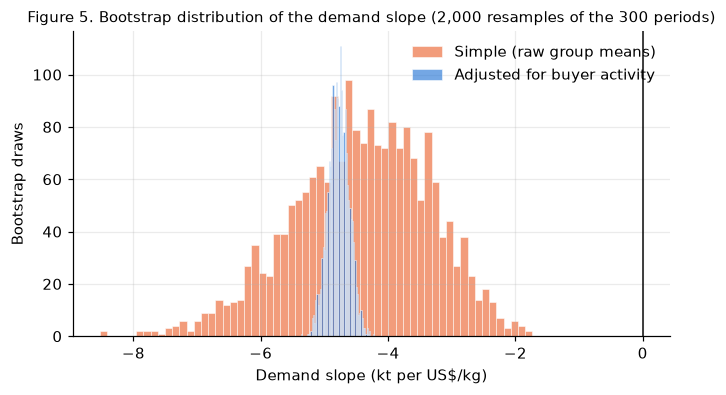

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for (k, v), colr in zip(boot.items(), [ORANGE, BLUE]):
    ax.hist(v, bins=60, color=colr, alpha=0.65, edgecolor="white", linewidth=0.5, label=k)
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("Demand slope (kt per US$/kg)"); ax.set_ylabel("Bootstrap draws")
ax.set_title("Figure 5. Bootstrap distribution of the demand slope (2,000 resamples of the 300 periods)", fontsize=10)
ax.legend(frameon=False); plt.show()

## 3.3 From a slope to an elasticity

Price elasticity of demand (Unit 1): $\varepsilon = \dfrac{\%\Delta Q}{\%\Delta P} = \dfrac{\Delta Q}{\Delta P}\cdot\dfrac{P}{Q}$.

With a **linear** demand curve the slope is constant, but the elasticity changes along the curve because $P/Q$ changes. So we must say **where** we evaluate it. The natural point is the **reference market**: normal harvest and buyer activity = 0, where P ≈ 10 US\$/kg and Q ≈ 100 kt. That is also the "normal release" scenario used in Q5–Q6. We also report the elasticity at the two ends of the observed range.

In [14]:
def elasticity(slope, P, Q): return slope * P / Q
rows = []
for lab, g in [("Unfavourable harvest, B=0", -1.5), ("Reference: normal harvest, B=0", 0.0), ("Favourable harvest, B=0", 1.5)]:
    P0, Q0 = adj.loc[g, "P at B=0"], adj.loc[g, "Q at B=0"]
    rows.append({"evaluation point": lab, "P": P0, "Q": Q0,
                 "elasticity": elasticity(slope_adj, P0, Q0),
                 "elasticity low": elasticity(ranges.loc["Adjusted for buyer activity", "2.5th pct"], P0, Q0),
                 "elasticity high": elasticity(ranges.loc["Adjusted for buyer activity", "97.5th pct"], P0, Q0)})
pd.DataFrame(rows).set_index("evaluation point").round(2)

,P,Q,elasticity,elasticity low,elasticity high
evaluation point,,,,,
"Unfavourable harvest, B=0",11.64,92.34,-0.60,-0.64,-0.56
"Reference: normal harvest, B=0",9.99,99.95,-0.48,-0.51,-0.45
"Favourable harvest, B=0",8.40,107.86,-0.37,-0.40,-0.35


**Economic meaning:** around the reference market, a 1% higher price reduces the quantity buyers purchase by about 0.5%. Demand is **inelastic** (|ε| < 1): buyers cut back only a little when coffee becomes dearer.

When a supply shortfall raises the price, the price rises *proportionally more* than the quantity falls, so sellers' revenue goes **up**. This is consistent with the Q1 finding that revenue was highest in unfavourable harvests.

## 3.4 Comparison with "treating all observations alike"

In [16]:
b_pooled = np.polyfit(coff_mark["price_usd_kg"], coff_mark["quantity_kt"], 1)[0]
b_ols_ctrl = ols(coff_mark["quantity_kt"], coff_mark["price_usd_kg"], coff_mark["buyer_activity"])[1]
Pref, Qref = adj.loc[0.0, "P at B=0"], adj.loc[0.0, "Q at B=0"]
comp = pd.DataFrame({
    "slope (kt per US$/kg)": [b_pooled, b_ols_ctrl, slope_simple, slope_adj],
    "source of price variation": ["everything (mostly demand shifts)",
                                  "everything except observed buyer activity",
                                  "weather only (supply shifts)",
                                  "weather only, observed demand held fixed"]},
    index=["Pooled regression Q on P (Q1)", "Regression Q on P + buyer activity",
           "Weather comparison, simple", "Weather comparison, adjusted"])
comp["elasticity at reference"] = comp["slope (kt per US$/kg)"] * Pref / Qref
comp.round(2)

,slope (kt per US$/kg),source of price variation,elasticity at reference
Pooled regression Q on P (Q1),4.49,everything (mostly demand shifts),0.45
Regression Q on P + buyer activity,-4.24,everything except observed buyer activity,-0.42
"Weather comparison, simple",-4.40,weather only (supply shifts),-0.44
"Weather comparison, adjusted",-4.78,"weather only, observed demand held fixed",-0.48


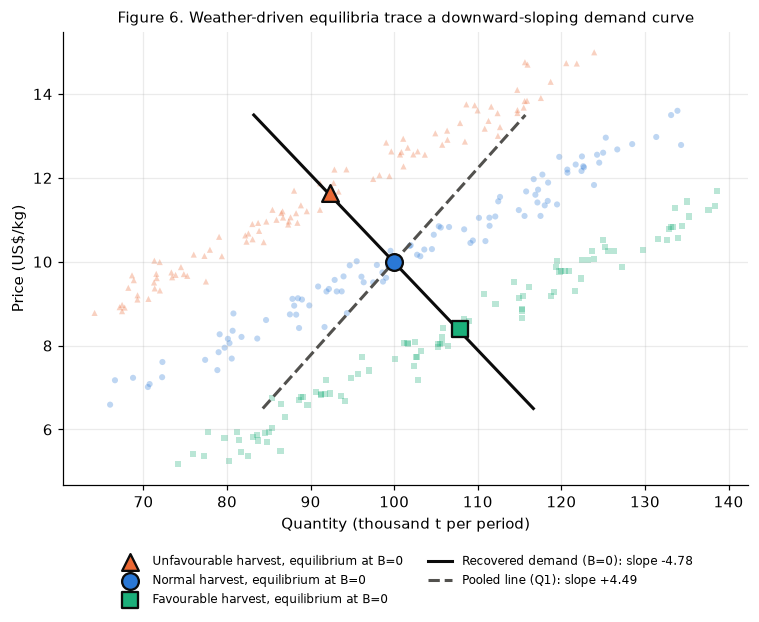

In [18]:
fig, ax = plt.subplots(figsize=(7, 5.8))
styles = {-1.5: (ORANGE, "^", "Unfavourable"), 0.0: (BLUE, "o", "Normal"), 1.5: (AQUA, "s", "Favourable")}
for g, (colr, mk, lab) in styles.items():
    d = coff_mark[coff_mark["growing_conditions"] == g]
    ax.scatter(d["quantity_kt"], d["price_usd_kg"], s=16, color=colr, marker=mk, alpha=0.3, edgecolor="none")
    ax.scatter(adj.loc[g, "Q at B=0"], adj.loc[g, "P at B=0"], s=120, color=colr, marker=mk,
               edgecolor=INK, linewidth=1.5, zorder=5, label=f"{lab} harvest, equilibrium at B=0")
pg = np.linspace(6.5, 13.5, 50)
ax.plot(Qref + slope_adj * (pg - Pref), pg, color=INK, lw=2, label=f"Recovered demand (B=0): slope {slope_adj:.2f}")
a_pool = np.polyfit(coff_mark["price_usd_kg"], coff_mark["quantity_kt"], 1)
ax.plot(np.polyval(a_pool, pg), pg, color=MUTED, lw=2, ls="--", label=f"Pooled line (Q1): slope +{b_pooled:.2f}")
ax.set_xlabel("Quantity (thousand t per period)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 6. Weather-driven equilibria trace a downward-sloping demand curve", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout(); plt.show()

- The pooled line slopes **up** (+4.5) because most price variation in the data comes from demand shifts, which trace supply.
- Holding *observed* buyer activity fixed in an ordinary regression flips the sign and here lands fairly close (−4.2), but **nothing guarantees that**. Unobserved demand shocks still move price and quantity together, so this regression still mixes demand and supply variation. Its validity rests on there being no unobserved demand shocks; the weather comparison only needs them to be unrelated to the weather.
- The weather comparison gives about **−4.4 (simple)** and **−4.8 (adjusted)** kt per US\$/kg. The three adjusted equilibria lie almost on one straight line, which supports the linear approximation.


## 3.5 Do observed buyer conditions change the interpretation?

In [20]:
# (a) balance: observed demand conditions across harvest groups
display(gm[["buyer_activity"]].rename(columns={"buyer_activity": "mean buyer_activity"}).round(2))
# (b) linearity: slope between neighbouring adjusted equilibria
s1 = (adj.loc[0.0, "Q at B=0"] - adj.loc[-1.5, "Q at B=0"]) / (adj.loc[0.0, "P at B=0"] - adj.loc[-1.5, "P at B=0"])
s2 = (adj.loc[1.5, "Q at B=0"] - adj.loc[0.0, "Q at B=0"]) / (adj.loc[1.5, "P at B=0"] - adj.loc[0.0, "P at B=0"])
print(f"Slope unfavourable→normal: {s1:.2f};  normal→favourable: {s2:.2f}")
# (c) same response when buyers are more or less active?
med = coff_mark["buyer_activity"].median()
for lab, d in [("buyer_activity below median", coff_mark[coff_mark["buyer_activity"] < med]),
               ("buyer_activity above median", coff_mark[coff_mark["buyer_activity"] >= med])]:
    print(f"{lab:30s} n={len(d)}  slope = {demand_slope(d):.2f}")

,mean buyer_activity
growing_conditions,
-1.5,-0.07
0.0,0.20
1.5,-0.15


Slope unfavourable→normal: -4.62;  normal→favourable: -4.97
buyer_activity below median    n=150  slope = -4.62
buyer_activity above median    n=150  slope = -4.97


**What the checks say (fill in):**
- *Balance:* mean buyer activity is close to 0 in every group. The normal group happens to be a bit higher (+0.20), which pushes its raw P and Q up. That is why the simple comparison uses the two extreme groups and why the adjustment helps.
- *Linearity:* the two neighbouring slopes are similar (≈ −4.6 and ≈ −5.0), so a straight line is a reasonable approximation over the observed range.
- *Stable slope:* the slope is similar whether buyers are more or less active. Buyer activity seems to shift demand *in parallel* rather than change its steepness.
- *Adjusting barely moves the estimate* (−4.4 → −4.8, with overlapping ranges) but makes it **much more precise**. The result does not hinge on buyer conditions.

| What strengthens the argument (checkable) | What we must **assume** (not checkable) |
|---|---|
| Strong price differences across harvest groups (relevance) | Weather does not enter demand directly (exclusion) |
| Buyer activity balanced across groups | Weather is independent of *unobserved* demand shocks |
| Adjusted equilibria on a line; stable slope across subsamples | No storage or carry-over and no anticipation (no stockpiling on harvest news) |
| Estimate robust to adjusting for buyer activity | Same buyers, same quality, competitive market clearing in every period |

**What would cast doubt:** buyer activity systematically different across harvest groups; a slope that changes a lot between subsamples; evidence that bad harvests are announced early and buyers stockpile.

## 3.6 Limitations in plain language
- We learn demand only **over the range of prices the weather produced** (≈ US\$8–12/kg). Outside it, the straight line is an extrapolation.
- It is one **average** response for this stylised market: it says nothing about individual buyers or other coffee grades.
- With only three weather levels, the estimate effectively rests on **three points**. The bootstrap range (≈ ±0.3 kt per US\$/kg adjusted, wider for the simple version) shows the sampling uncertainty, but not the risk that the assumptions are wrong.
- It is a **short-run** response within a selling period. Over longer horizons buyers can switch origins or build stocks, and demand would likely be more elastic.

---
# Question 5: Predict a new market outcome

## 5.1 New scenario

`coffee_forecast_scenarios.csv` describes a **short selling window after harvest**:
- The coffee is already harvested and committed to sale. There is **no storage, no imports, no alternative outlet**, so all of it is sold whatever the price.
- Supply is **perfectly inelastic** at the available volume $\bar Q$. Price no longer changes how much is offered. It only decides **who buys** the fixed amount.
- The demand curve from Q3 remains valid.

Equilibrium is where the demand curve meets the vertical supply line:

$$D(P^*) = a + b\,P^* = \bar Q \quad\Longrightarrow\quad P^* = \frac{a - \bar Q}{-b}, \qquad \text{Revenue} = P^* \times \bar Q .$$


## 5.2 The demand curve at reference conditions

We need the **level** of demand (intercept $a$) as well as the slope $b$. We take both from the Q3 logic: 
1) predict price from the weather and buyer activity
2) regress quantity on that weather-driven price and buyer activity. 

Step (2) uses only the price variation caused by the weather, so its price coefficient equals the Q3 adjusted slope. Setting B = 0 gives the reference demand curve.

In [46]:
def fit_demand(d):
    G, B = d["growing_conditions"], d["buyer_activity"]
    cP = ols(d["price_usd_kg"], G, B)
    P_weather = cP[0] + cP[1] * G + cP[2] * B        # price explained by weather (and B)
    a, b, c = ols(d["quantity_kt"], P_weather, B)     # Q = a + b*P + c*B
    return a, b, c

a_D, b_D, c_D = fit_demand(coff_mark)
print(f"Demand: Q = {a_D:.1f} {b_D:+.2f}·P {c_D:+.1f}·buyer_activity")
print(f"At reference (B = 0): Q = {a_D:.1f} {b_D:+.2f}·P   (slope = Q3 adjusted slope {slope_adj:.2f})")

scen = pd.read_csv("data/coffee_forecast_scenarios.csv")
scen

Demand: Q = 147.9 -4.78·P +14.9·buyer_activity
At reference (B = 0): Q = 147.9 -4.78·P   (slope = Q3 adjusted slope -4.78)


,scenario,release_kt,buyer_activity,explanation
0,Normal release,100,0,Normal reference volume committed to sale
1,Smaller release,92,0,"Eight percent less than normal, all committed ..."


## 5.3 Predictions: price and revenue in each scenario

In [48]:
def p_star(Qbar, a=a_D, b=b_D): return (a - Qbar) / (-b)

pred = scen[["scenario", "release_kt"]].copy()
pred["pred_price_usd_kg"] = p_star(pred["release_kt"])
pred["pred_revenue_musd"] = pred["pred_price_usd_kg"] * pred["release_kt"]

# What the pooled Q1 line would predict (treating it as if it were demand)
b_pool, a_pool = np.polyfit(coff_mark["price_usd_kg"], coff_mark["quantity_kt"], 1)
pred["pooled_line_price"] = (pred["release_kt"] - a_pool) / b_pool
pred["pooled_line_revenue"] = pred["pooled_line_price"] * pred["release_kt"]
pred.round(2)

,scenario,release_kt,pred_price_usd_kg,pred_revenue_musd,pooled_line_price,pooled_line_revenue
0,Normal release,100,10.03,1002.82,10.00,1000.39
1,Smaller release,92,11.70,1076.64,8.22,756.39


In [52]:
n, s = pred.set_index("scenario").loc["Normal release"], pred.set_index("scenario").loc["Smaller release"]
pct = lambda new, old: 100 * (new / old - 1)
print(f"Quantity: {pct(s.release_kt, n.release_kt):+.1f}%")
print(f"Price:    {pct(s.pred_price_usd_kg, n.pred_price_usd_kg):+.1f}%")
print(f"Revenue:  {pct(s.pred_revenue_musd, n.pred_revenue_musd):+.1f}%")

# The disequilibrium story: harvest falls but price initially stays at the normal level
P_old = n.pred_price_usd_kg
desired = a_D + b_D * P_old
print(f"\nAt the old price {P_old:.2f}: buyers want {desired:.1f} kt but only {s.release_kt:.0f} kt is available "
      f"→ excess demand of {desired - s.release_kt:.1f} kt")
print(f"Price rise needed to choke off that excess demand: {(desired - s.release_kt) / -b_D:.2f} US$/kg")

Quantity: -8.0%
Price:    +16.7%
Revenue:  +7.4%

At the old price 10.03: buyers want 100.0 kt but only 92 kt is available → excess demand of 8.0 kt
Price rise needed to choke off that excess demand: 1.67 US$/kg


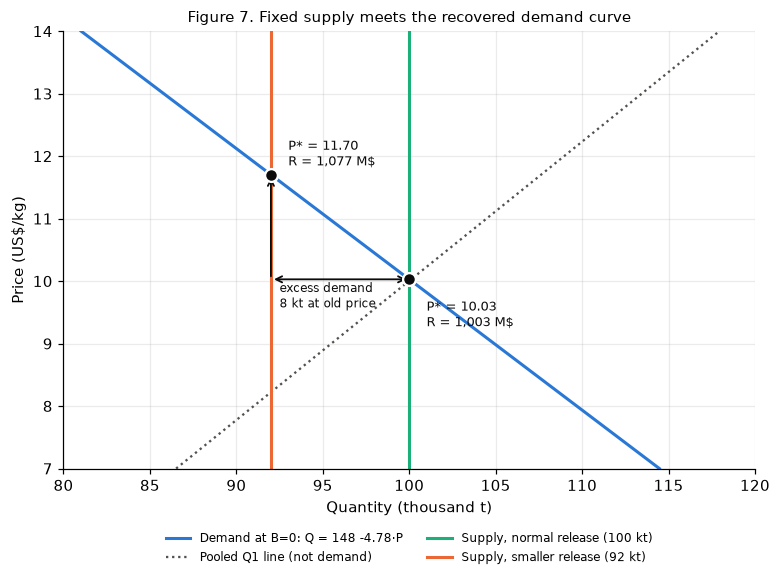

In [55]:
fig, ax = plt.subplots(figsize=(7.2, 5.4))
pg = np.linspace(7, 14, 50)
ax.plot(a_D + b_D * pg, pg, color=BLUE, lw=2, label=f"Demand at B=0: Q = {a_D:.0f} {b_D:.2f}·P")
ax.plot(a_pool + b_pool * pg, pg, color=MUTED, lw=1.5, ls=":", label="Pooled Q1 line (not demand)")
for Qbar, colr, lab in [(100, AQUA, "Supply, normal release (100 kt)"), (92, ORANGE, "Supply, smaller release (92 kt)")]:
    ax.axvline(Qbar, color=colr, lw=2, label=lab)
    P = p_star(Qbar)
    ax.scatter([Qbar], [P], s=70, color=INK, zorder=5, edgecolor="white", linewidth=1.5)
    dy = 0.15 if Qbar == 92 else -0.75
    ax.text(Qbar + 1, P + dy, f"P* = {P:.2f}\nR = {P*Qbar:,.0f} M$", fontsize=8.5, color=INK)
# excess demand at the old price
ax.annotate("", xy=(desired, P_old), xytext=(92, P_old),
            arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2))
ax.text(92.5, P_old - 0.45, f"excess demand\n{desired - 92:.0f} kt at old price", fontsize=8, color=INK)
ax.annotate("", xy=(92, p_star(92)), xytext=(92, P_old), arrowprops=dict(arrowstyle="->", color=INK, lw=1.2))
ax.set_xlim(80, 120); ax.set_ylim(7, 14)
ax.set_xlabel("Quantity (thousand t)"); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 7. Fixed supply meets the recovered demand curve", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout(); plt.show()


- With 100 kt the price settles at about the reference level (≈ US\$10/kg, revenue ≈ US\$1.0 bn).
- With 8% less coffee the price must rise until buyers *want* only 92 kt. Because demand is inelastic (|ε| ≈ 0.5), this takes a price rise of about 17% (8% ÷ 0.48). Revenue therefore **rises** by about 7%: sellers earn more by selling less.
- **Disequilibrium:** if the price stayed at the old level, buyers would want about 100 kt but only 92 kt exist. Buyers who miss out offer more, the price is bid up, and some buyers drop out along the demand curve until the remaining desired purchases equal 92 kt.
- **The pooled line predicts the opposite:** a *lower* price (≈ US\$8.2) and revenue falling by about a quarter, because it treats a supply curve as if it were demand.


## 5.4 How uncertain is the prediction?

There are two different questions here:
1. **The average price** across many such selling windows. Its uncertainty comes from estimating $a$ and $b$ from 300 periods.
2. **The price in one single window.** That period's own demand disturbance moves the demand curve left or right. With vertical supply, a demand shock of $u$ kt moves the price by $u/|b|$.

In [57]:
rng = np.random.default_rng(2026)
boot_P = []
for _ in range(2000):
    d = coff_mark.iloc[rng.integers(0, len(coff_mark), len(coff_mark))]
    a_, b_, _ = fit_demand(d)
    boot_P.append([p_star(100, a_, b_), p_star(92, a_, b_)])
boot_P = np.array(boot_P)

u = coff_mark["quantity_kt"] - (a_D + b_D * coff_mark["price_usd_kg"] + c_D * coff_mark["buyer_activity"])   # demand disturbances
sd_P_single = u.std() / -b_D

pred["avg_price_low"]  = np.percentile(boot_P, 2.5, axis=0)
pred["avg_price_high"] = np.percentile(boot_P, 97.5, axis=0)
pred["single_window_low"]  = pred["pred_price_usd_kg"] - 1.96 * sd_P_single
pred["single_window_high"] = pred["pred_price_usd_kg"] + 1.96 * sd_P_single
print(f"sd of demand disturbances ≈ {u.std():.2f} kt → sd of a single window's price ≈ {sd_P_single:.2f} US$/kg")
pred[["scenario", "pred_price_usd_kg", "avg_price_low", "avg_price_high",
      "single_window_low", "single_window_high", "pred_revenue_musd"]].round(2)

sd of demand disturbances ≈ 3.84 kt → sd of a single window's price ≈ 0.80 US$/kg


,scenario,pred_price_usd_kg,avg_price_low,avg_price_high,single_window_low,single_window_high,pred_revenue_musd
0,Normal release,10.03,9.93,10.12,8.45,11.60,1002.82
1,Smaller release,11.70,11.56,11.85,10.13,13.28,1076.64


## 5.5 Record the predictions

The next cell saves the predictions with a time stamp, so it is documented that they were made before seeing `coffee_forecast_reveal.csv`.

In [58]:
from datetime import datetime
pred["recorded_at"] = datetime.now().isoformat(timespec="seconds")
pred.to_csv("q5_predictions_recorded.csv", index=False)
pred[["scenario", "release_kt", "pred_price_usd_kg", "pred_revenue_musd", "recorded_at"]].round(2)

,scenario,release_kt,pred_price_usd_kg,pred_revenue_musd,recorded_at
0,Normal release,100,10.03,1002.82,2026-10-29T23:50:35
1,Smaller release,92,11.70,1076.64,2026-10-29T23:50:35


## 5.6 Compare with the new evidence (no refitting)

`coffee_forecast_reveal.csv`: 40 independent realisations of each scenario. We only compare.

In [60]:
assert Path("q5_predictions_recorded.csv").exists(), "Record the predictions first (5.5)"
rev = pd.read_csv("data/coffee_forecast_reveal.csv")
rev["revenue_musd"] = rev["price_usd_kg"] * rev["quantity_kt"]
obs = (rev.groupby("scenario")
          .agg(n=("price_usd_kg", "size"), mean_price=("price_usd_kg", "mean"),
               sd_price=("price_usd_kg", "std"), min_price=("price_usd_kg", "min"),
               max_price=("price_usd_kg", "max"), mean_revenue=("revenue_musd", "mean")))
obs["se_mean_price"] = obs["sd_price"] / np.sqrt(obs["n"])
cmp_ = obs.join(pred.set_index("scenario")[["pred_price_usd_kg", "avg_price_low", "avg_price_high",
                                             "single_window_low", "single_window_high", "pred_revenue_musd"]])
cmp_["error_mean_price"] = cmp_["mean_price"] - cmp_["pred_price_usd_kg"]
cmp_["share_in_single_band"] = [rev.loc[rev.scenario == s, "price_usd_kg"].between(r.single_window_low, r.single_window_high).mean()
                                for s, r in cmp_.iterrows()]
cmp_.T.round(2)

scenario,Normal release,Smaller release
n,40.00,40.00
mean_price,10.09,11.69
sd_price,0.77,0.73
min_price,8.59,10.23
max_price,11.56,13.42
mean_revenue,1009.13,1075.42
se_mean_price,0.12,0.12
pred_price_usd_kg,10.03,11.70
avg_price_low,9.93,11.56
avg_price_high,10.12,11.85


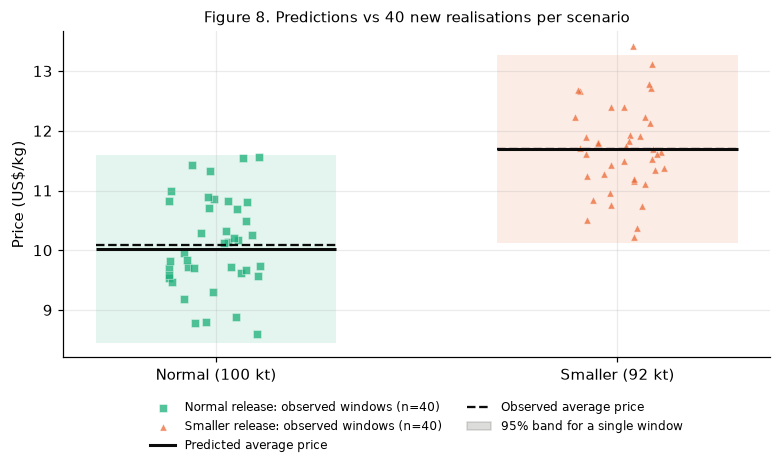

In [61]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for i, (sc, colr, mk) in enumerate([("Normal release", AQUA, "s"), ("Smaller release", ORANGE, "^")]):
    y = rev.loc[rev.scenario == sc, "price_usd_kg"]
    x = i + rng.uniform(-0.12, 0.12, len(y))
    ax.scatter(x, y, s=22, color=colr, marker=mk, alpha=0.75, edgecolor="white", linewidth=0.4,
               label=f"{sc}: observed windows (n={len(y)})")
    r = cmp_.loc[sc]
    ax.fill_between([i - 0.3, i + 0.3], r.single_window_low, r.single_window_high, color=colr, alpha=0.12, lw=0)
    ax.hlines(r.pred_price_usd_kg, i - 0.3, i + 0.3, color=INK, lw=2)
    ax.hlines(r.mean_price, i - 0.3, i + 0.3, color=INK, lw=1.5, ls="--")
ax.plot([], [], color=INK, lw=2, label="Predicted average price")
ax.plot([], [], color=INK, lw=1.5, ls="--", label="Observed average price")
ax.fill_between([], [], [], color=MUTED, alpha=0.2, label="95% band for a single window")
ax.set_xticks([0, 1], ["Normal (100 kt)", "Smaller (92 kt)"]); ax.set_ylabel("Price (US$/kg)")
ax.set_title("Figure 8. Predictions vs 40 new realisations per scenario", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
fig.tight_layout(); plt.show()